# 05_03 Sampling Distributions and the Standard Error

**Learning objectives**
- Separate three things that beginners mix up: the **population** (fixed), the **sample** (random) and the **sampling distribution** of a statistic (what we would see over many repeated samples).
- Compute and interpret the **standard error** of a mean, a proportion, a median and a difference of means, and apply the **finite population correction**.
- Know the exact sampling distributions for Normal data: $(n-1)s^2/\sigma^2\sim\chi^2_{n-1}$ and $(\bar X-\mu)/(s/\sqrt n)\sim t_{n-1}$; understand **Bessel's correction** ($n-1$ in the sample variance).
- Read a **confidence interval** correctly and check its coverage by simulation.

**Prerequisites:** [05_01 Law of large numbers](05_01_law_of_large_numbers.ipynb), [05_02 Central limit theorem](05_02_central_limit_theorem.ipynb), [02_08 t, chi-square and F](../../module_02_continuous/notebooks/02_08_t_chisquare_f.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Statistic:** any function of the sample, such as $\bar X$, $s^2$, the median or the maximum. Because the sample is random, **a statistic is a random variable** with its own distribution.
- **CLT (05_02):** for large $n$, $\bar X\approx N(\mu,\sigma^2/n)$.
- **Chi-square and t (02_08):** $\chi^2_\nu$ is a sum of $\nu$ squared standard Normals; $t_\nu=Z/\sqrt{\chi^2_\nu/\nu}$.
- **Variance of an independent sum:** $\mathrm{Var}(\sum X_i)=n\sigma^2$.

## 3. Intuition and story

A delivery company has 20,000 deliveries this month. You cannot afford to time them all, so you time **40** of them and report the average. If a colleague timed a *different* 40, they would get a different average. And a third colleague, a third one. **The spread of those averages across all the possible samples is what tells you how much to trust yours.** That spread is the **sampling distribution**, and its standard deviation is the **standard error (SE)**.

Everything in classical inference is built on this picture:

| Word | Meaning | Example |
|---|---|---|
| Population | the full set (fixed, usually unknown) | all 20,000 delivery times |
| Parameter | a number describing the population | true mean $\mu$ |
| Sample | the data we actually have (random) | the 40 timed deliveries |
| Statistic | a number computed from the sample (random) | $\bar x$ |
| Sampling distribution | distribution of the statistic over repeated samples | the histogram of many $\bar x$ values |
| Standard error | standard deviation of the sampling distribution | $\sigma/\sqrt n$ |

**Standard deviation** describes how spread out *individual observations* are; **standard error** describes how spread out an *estimate* is. The first does not shrink with $n$; the second does.

## 4. Formal definition and key formulas

For a statistic $T$ computed from an iid sample, the **sampling distribution** is the distribution of $T$ and the **standard error** is $\mathrm{SE}(T)=\sqrt{\mathrm{Var}(T)}$ (often estimated by plugging in sample values).

| Statistic | Standard error | Exact or approximate |
|---|---|---|
| Mean $\bar X$ | $\sigma/\sqrt n$ (estimated by $s/\sqrt n$) | exact (variance); Normal shape by CLT |
| Proportion $\hat p$ | $\sqrt{p(1-p)/n}$ (estimated by $\sqrt{\hat p(1-\hat p)/n}$) | exact |
| Difference of means (independent) | $\sqrt{\sigma_1^2/n_1+\sigma_2^2/n_2}$ | exact |
| Median (Normal data) | $\approx1.2533\,\sigma/\sqrt n$ | large $n$ |
| Mean, sampling **without replacement** from $N$ | $\dfrac\sigma{\sqrt n}\sqrt{\dfrac{N-n}{N-1}}$ | exact (finite population correction) |

**Normal-data results:** $\ \dfrac{(n-1)s^2}{\sigma^2}\sim\chi^2_{n-1}$, $\ \bar X$ and $s^2$ are independent, $\ \dfrac{\bar X-\mu}{s/\sqrt n}\sim t_{n-1}$.

**Confidence interval for a mean:** $\bar x\pm t_{n-1,\,1-\alpha/2}\;s/\sqrt n$. The 95 % refers to the **procedure**: over many repeated samples about 95 % of such intervals contain $\mu$.

## 5. Derivations

### 5.1 The standard error of the mean
$\mathrm{Var}(\bar X)=\mathrm{Var}\!\big(\tfrac1n\sum X_i\big)=\tfrac1{n^2}\cdot n\sigma^2=\sigma^2/n$ (independence), so $\mathrm{SE}(\bar X)=\sigma/\sqrt n$. **In plain words.** Each observation contributes noise $\sigma$; the average divides the *sum's* noise ($\sigma\sqrt n$) by $n$.

### 5.2 Why the sample variance divides by $n-1$ (Bessel)
Write $\sum(X_i-\bar X)^2=\sum(X_i-\mu)^2-n(\bar X-\mu)^2$. Taking expectations: $n\sigma^2-n\cdot\sigma^2/n=(n-1)\sigma^2$. So $E\big[\sum(X_i-\bar X)^2\big]=(n-1)\sigma^2$ and dividing by $n-1$ makes $s^2$ **unbiased**. **In plain words.** The deviations are measured from $\bar X$, which is *itself fitted to the data* and sits closer to the points than $\mu$ does; that shrinks the sum by exactly one $\sigma^2$, and the $n-1$ puts it back.

### 5.3 $(n-1)s^2/\sigma^2\sim\chi^2_{n-1}$ for Normal data
$\sum\big(\tfrac{X_i-\mu}{\sigma}\big)^2\sim\chi^2_n$. Subtracting the fitted mean removes one degree of freedom: $\sum\big(\tfrac{X_i-\bar X}{\sigma}\big)^2\sim\chi^2_{n-1}$, independent of $\bar X$ (a special property of the Normal). Hence $E[s^2]=\sigma^2$ and $\mathrm{Var}(s^2)=2\sigma^4/(n-1)$.

### 5.4 The t statistic
$T=\dfrac{\bar X-\mu}{s/\sqrt n}=\dfrac{Z}{\sqrt{\chi^2_{n-1}/(n-1)}}$ with $Z=\frac{\bar X-\mu}{\sigma/\sqrt n}\sim N(0,1)$ independent of $s^2$, which is the definition of $t_{n-1}$. We pay for estimating $\sigma$ by $s$ with heavier tails (04_02: 1.96 becomes 2.04 at 30 d.f.).

### 5.5 Finite population correction
Sampling $n$ **without replacement** from $N$ makes the observations negatively correlated: $\mathrm{Cov}(X_i,X_j)=-\sigma^2/(N-1)$. Then $\mathrm{Var}(\bar X)=\frac{\sigma^2}{n}\big[1+(n-1)\tfrac{-1}{N-1}\big]=\frac{\sigma^2}n\cdot\frac{N-n}{N-1}$. **In plain words.** If you sample a large share of the population there is less left to be uncertain about; at $n=N$ the SE is zero (you measured everyone). For $n/N<5\,\%$ the correction is invisible.

### 5.6 SE of the median
For Normal data the sample median has $\mathrm{Var}\approx\frac{\pi}{2}\frac{\sigma^2}{n}$, i.e. SE $=1.2533\,\sigma/\sqrt n$: the median is **25 % noisier** than the mean for Normal data (but far more robust for heavy tails). In general $\mathrm{SE}(\text{median})\approx\dfrac1{2f(m)\sqrt n}$ where $f$ is the density at the median.

### 5.7 What "95 % confidence" really says
$P\big(|T|\le t_{n-1,0.975}\big)=0.95$ *before* the data are drawn. Rearranging gives an interval that covers $\mu$ in 95 % of repeated samples. **After** the data are in, the interval either contains $\mu$ or it does not; "95 % probability that $\mu$ is inside *this* interval" is not the correct reading (06 and 07 discuss the Bayesian alternative).

## 6. Properties and relationships

- **Sampling distribution depends on the statistic:** the same data give different SEs for the mean, the median and the maximum (7.5).
- **SE shrinks as $1/\sqrt n$** (05_01) but never to zero for a sample; a **census** has SE 0.
- **Bias versus variance:** the standard error measures the *random* error only. A biased sample (a survey that misses a group) has a small SE and a wrong answer.
- **Standardizing links everything:** $z$ (known $\sigma$), $t$ (estimated $\sigma$), $\chi^2$ (variance), $F$ (ratio of variances, 02_08) are all sampling distributions of natural statistics under Normal data.
- **Estimated SE is itself random:** with small $n$ the estimate of the SE is noisy, which is why we use $t$ rather than $z$.
- **Where SE shows up:** error bars, confidence intervals (05_03), hypothesis tests (06), sample-size calculations (05_01), the bootstrap (05_04).

## 7. 2D visuals

### 7.1 One population, many samples
A skewed population of 20,000 delivery times (left). Each histogram on the right is the **sampling distribution of the mean** from 20,000 repeated samples of size $n$. It is centred on the population mean and narrows like $\sigma/\sqrt n$; the dashed curve is the CLT Normal.

population: N = 20000, mean = 30.042, standard deviation = 15.066, skewness = 1.023


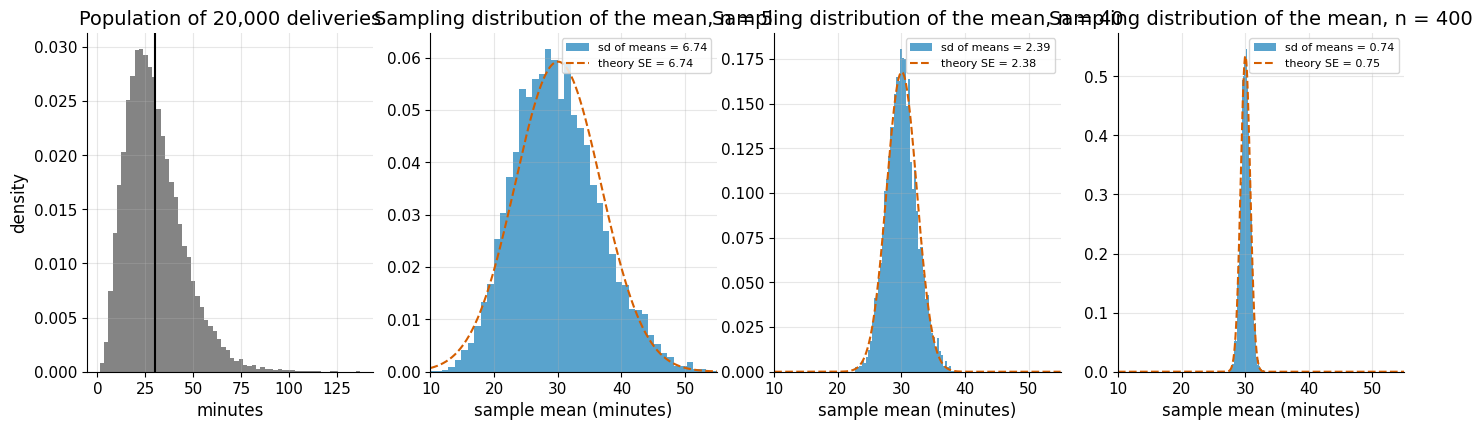

In [2]:
pop_rng = np.random.default_rng(2025)
population = pop_rng.gamma(shape=4, scale=7.5, size=20_000)         # delivery times in minutes
N = population.size
mu_pop, sigma_pop = population.mean(), population.std()               # population parameters (ddof = 0)
print(f"population: N = {N}, mean = {mu_pop:.3f}, standard deviation = {sigma_pop:.3f}, skewness = {stats.skew(population):.3f}")

def repeated_means(n, reps, generator):
    idx = np.array([generator.choice(N, size=n, replace=False) for _ in range(reps)])
    return population[idx].mean(axis=1)

fig, axes = plt.subplots(1, 4, figsize=(17, 4.4))
axes[0].hist(population, bins=60, density=True, color=NEUTRAL, alpha=0.8)
axes[0].axvline(mu_pop, color="black")
axes[0].set_title("Population of 20,000 deliveries")
axes[0].set_xlabel("minutes"); axes[0].set_ylabel("density")
x = np.linspace(10, 55, 400)
for ax, n in zip(axes[1:], [5, 40, 400]):
    means = repeated_means(n, 6000, rng)
    se = sigma_pop / np.sqrt(n) * np.sqrt((N - n) / (N - 1))
    ax.hist(means, bins=50, density=True, color=MAIN, alpha=0.65, label=f"sd of means = {means.std():.2f}")
    ax.plot(x, stats.norm(mu_pop, se).pdf(x), "--", color=HIGHLIGHT, label=f"theory SE = {se:.2f}")
    ax.set_title(f"Sampling distribution of the mean, n = {n}")
    ax.set_xlabel("sample mean (minutes)"); ax.set_xlim(10, 55); ax.legend(fontsize=8)
plt.show()

### 7.2 The standard error is not the standard deviation
Left: the spread of **individual** observations does not shrink with $n$; the spread of the **mean** does, like $1/\sqrt n$ (log-log slope $-1/2$). Right: the SE of the mean, the median and the 90th percentile for the same population: different statistics, different sampling distributions.

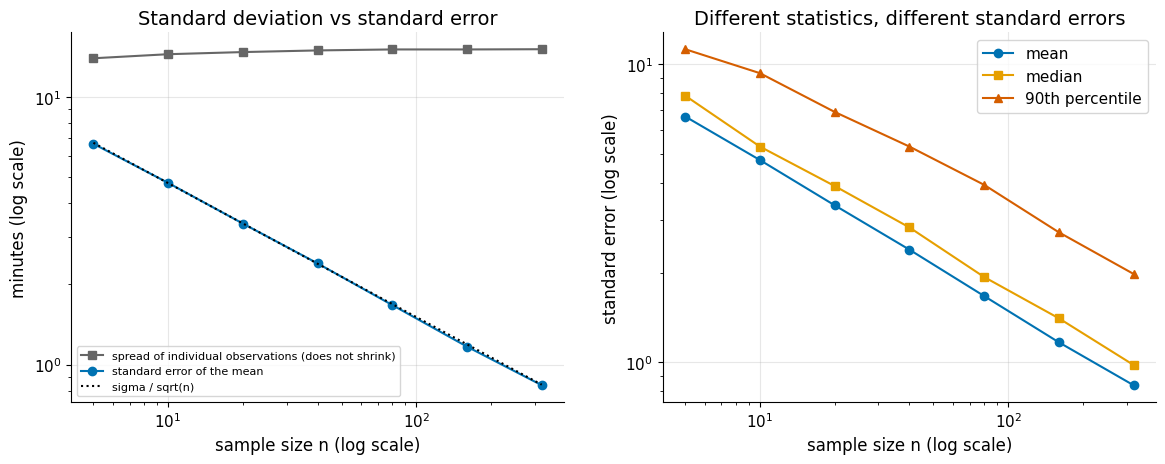

slope of the SE of the mean: -0.502 ; median / mean SE ratio at n = 320: 1.169


In [3]:
ns = np.array([5, 10, 20, 40, 80, 160, 320])
reps = 4000
mean_se, median_se, q90_se, sd_obs = [], [], [], []
for n in ns:
    idx = np.array([rng.choice(N, size=n, replace=False) for _ in range(reps)])
    sample = population[idx]
    mean_se.append(sample.mean(axis=1).std()); median_se.append(np.median(sample, axis=1).std())
    q90_se.append(np.quantile(sample, 0.9, axis=1).std()); sd_obs.append(sample.std(axis=1, ddof=1).mean())
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.8))
ax_a.loglog(ns, sd_obs, "s-", color=NEUTRAL, label="spread of individual observations (does not shrink)")
ax_a.loglog(ns, mean_se, "o-", color=MAIN, label="standard error of the mean")
ax_a.loglog(ns, sigma_pop / np.sqrt(ns), ":", color="black", label="sigma / sqrt(n)")
ax_a.set_title("Standard deviation vs standard error")
ax_a.set_xlabel("sample size n (log scale)"); ax_a.set_ylabel("minutes (log scale)"); ax_a.legend(fontsize=8)
ax_b.loglog(ns, mean_se, "o-", color=MAIN, label="mean")
ax_b.loglog(ns, median_se, "s-", color=COLORS[1], label="median")
ax_b.loglog(ns, q90_se, "^-", color=HIGHLIGHT, label="90th percentile")
ax_b.set_title("Different statistics, different standard errors")
ax_b.set_xlabel("sample size n (log scale)"); ax_b.set_ylabel("standard error (log scale)"); ax_b.legend()
plt.show()
print("slope of the SE of the mean:", round(np.polyfit(np.log(ns), np.log(mean_se), 1)[0], 3), "; median / mean SE ratio at n = 320:", round(median_se[-1] / mean_se[-1], 3))

### 7.3 The distribution of the sample variance and of the t statistic (Normal data)
For Normal data the exact results hold at *any* $n$, even $n=5$. Left: $(n-1)s^2/\sigma^2$ against the chi-square density. Right: the studentized mean against the t density and the (wrong) Normal density.

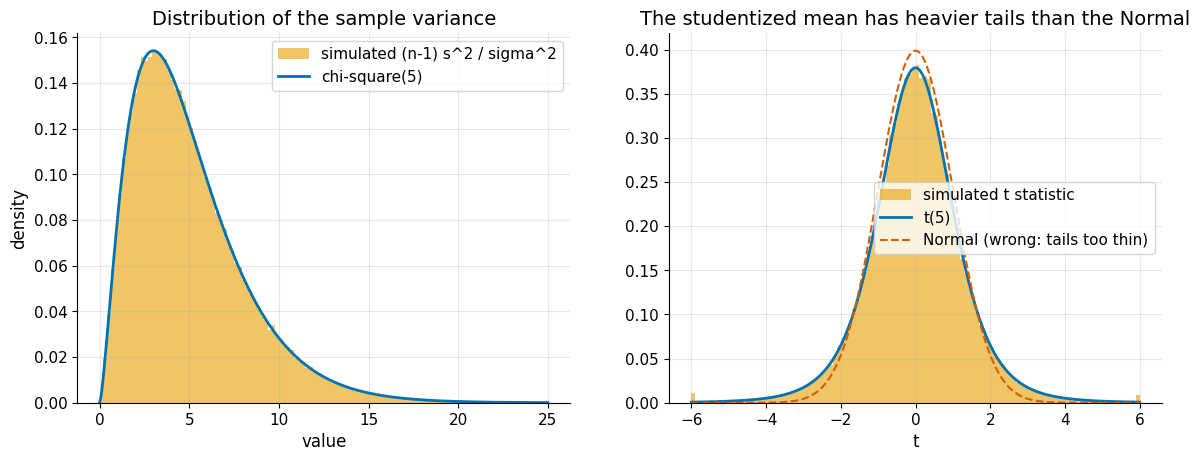

KS test vs chi-square: 0.0021 | KS vs t: 0.0022 | KS vs Normal: 0.031


In [4]:
n, sigma, mu = 6, 2.0, 10.0
data = rng.normal(mu, sigma, (200_000, n))
chi = (n - 1) * data.var(axis=1, ddof=1) / sigma**2
t_stat = (data.mean(axis=1) - mu) / (data.std(axis=1, ddof=1) / np.sqrt(n))
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(14, 4.8))
xs = np.linspace(0, 25, 400)
ax_a.hist(chi, bins=120, range=(0, 25), density=True, color=SIM, alpha=0.6, label="simulated (n-1) s^2 / sigma^2")
ax_a.plot(xs, stats.chi2(n - 1).pdf(xs), color=MAIN, linewidth=2, label=f"chi-square({n - 1})")
ax_a.set_title("Distribution of the sample variance")
ax_a.set_xlabel("value"); ax_a.set_ylabel("density"); ax_a.legend()
xt = np.linspace(-6, 6, 400)
ax_b.hist(np.clip(t_stat, -6, 6), bins=120, range=(-6, 6), density=True, color=SIM, alpha=0.6, label="simulated t statistic")
ax_b.plot(xt, stats.t(n - 1).pdf(xt), color=MAIN, linewidth=2, label=f"t({n - 1})")
ax_b.plot(xt, stats.norm.pdf(xt), "--", color=HIGHLIGHT, label="Normal (wrong: tails too thin)")
ax_b.set_title("The studentized mean has heavier tails than the Normal")
ax_b.set_xlabel("t"); ax_b.legend()
plt.show()
print("KS test vs chi-square:", round(stats.kstest(chi, stats.chi2(n - 1).cdf).statistic, 4), "| KS vs t:", round(stats.kstest(t_stat, stats.t(n - 1).cdf).statistic, 4), "| KS vs Normal:", round(stats.kstest(t_stat, stats.norm.cdf).statistic, 4))
assert stats.kstest(chi, stats.chi2(n - 1).cdf).statistic < 0.005 and stats.kstest(t_stat, stats.t(n - 1).cdf).statistic < 0.005

### 7.4 Bessel's correction: why $n-1$
Dividing by $n$ makes the sample variance too small on average by the factor $(n-1)/n$; dividing by $n-1$ removes the bias. The effect is large for small samples and vanishes for large ones.

  n  mean of s^2 (divide by n)  theory (n-1)/n sigma^2  mean of s^2 (divide by n-1)  true sigma^2
  2                     1.9975                  2.0000                       3.9950           4.0
  3                     2.6582                  2.6667                       3.9873           4.0
  5                     3.1945                  3.2000                       3.9932           4.0
 10                     3.5976                  3.6000                       3.9973           4.0
 30                     3.8662                  3.8667                       3.9995           4.0
100                     3.9582                  3.9600                       3.9982           4.0


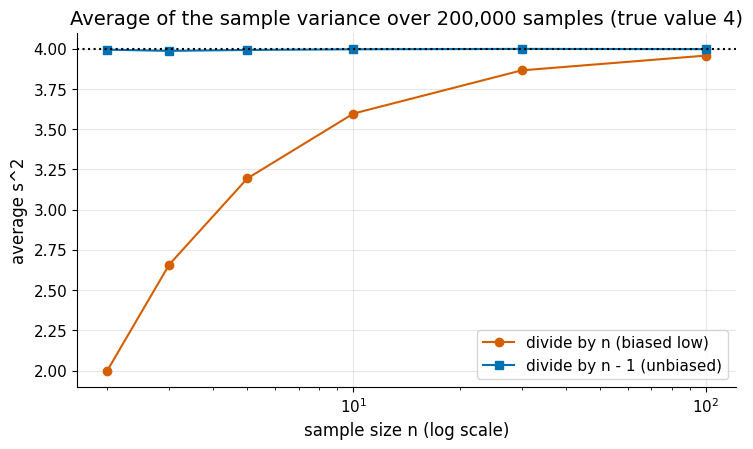

In [5]:
rows = []
sigma2 = 4.0
for n in [2, 3, 5, 10, 30, 100]:
    d = rng.normal(0, np.sqrt(sigma2), (200_000, n))
    rows.append({"n": n, "mean of s^2 (divide by n)": d.var(axis=1, ddof=0).mean(), "theory (n-1)/n sigma^2": (n - 1) / n * sigma2,
                 "mean of s^2 (divide by n-1)": d.var(axis=1, ddof=1).mean(), "true sigma^2": sigma2})
bessel = pd.DataFrame(rows)
print(bessel.round(4).to_string(index=False))
assert np.allclose(bessel["mean of s^2 (divide by n)"], bessel["theory (n-1)/n sigma^2"], rtol=0.02)
assert np.allclose(bessel["mean of s^2 (divide by n-1)"], sigma2, rtol=0.02)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.plot(bessel["n"], bessel["mean of s^2 (divide by n)"], "o-", color=HIGHLIGHT, label="divide by n (biased low)")
ax.plot(bessel["n"], bessel["mean of s^2 (divide by n-1)"], "s-", color=MAIN, label="divide by n - 1 (unbiased)")
ax.axhline(sigma2, color="black", linestyle=":")
ax.set_xscale("log"); ax.set_title("Average of the sample variance over 200,000 samples (true value 4)")
ax.set_xlabel("sample size n (log scale)"); ax.set_ylabel("average s^2"); ax.legend()
plt.show()

### 7.5 The finite population correction
Sampling without replacement from a small population (N = 200) reduces the SE by $\sqrt{(N-n)/(N-1)}$. The simulated SE follows the corrected formula, not the plain $\sigma/\sqrt n$, once $n/N$ is no longer small.

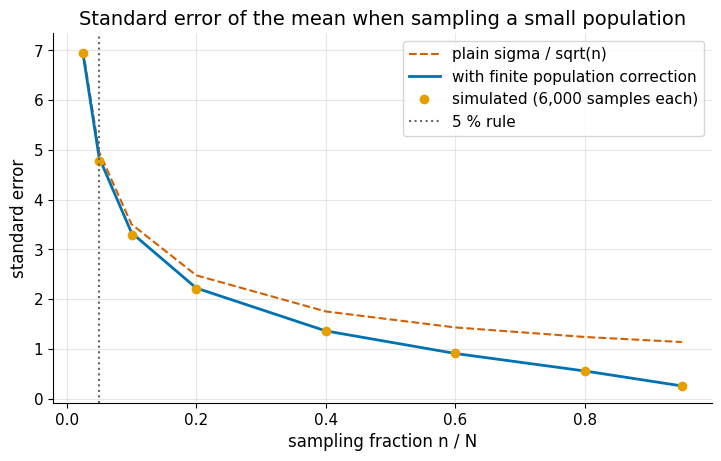

max relative gap simulated vs corrected formula: 0.018


In [6]:
small = population[:200]
mu_s, sd_s = small.mean(), small.std()
fractions, simulated, plain, corrected = [], [], [], []
for n in [5, 10, 20, 40, 80, 120, 160, 190]:
    sims = np.array([rng.choice(200, n, replace=False) for _ in range(6000)])
    simulated.append(small[sims].mean(axis=1).std()); plain.append(sd_s / np.sqrt(n)); corrected.append(sd_s / np.sqrt(n) * np.sqrt((200 - n) / 199)); fractions.append(n / 200)
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(fractions, plain, "--", color=HIGHLIGHT, label="plain sigma / sqrt(n)")
ax.plot(fractions, corrected, color=MAIN, linewidth=2, label="with finite population correction")
ax.plot(fractions, simulated, "o", color=SIM, label="simulated (6,000 samples each)")
ax.axvline(0.05, color=NEUTRAL, linestyle=":", label="5 % rule")
ax.set_title("Standard error of the mean when sampling a small population")
ax.set_xlabel("sampling fraction n / N"); ax.set_ylabel("standard error"); ax.legend()
plt.show()
print("max relative gap simulated vs corrected formula:", round(float(np.max(np.abs(np.array(simulated) / np.array(corrected) - 1))), 3))
assert np.max(np.abs(np.array(simulated) / np.array(corrected) - 1)) < 0.04

### 7.6 The interval 'dance': what 95 % coverage looks like
Sixty samples of 10 observations from a Normal population (mean 50, SD 12), each with its own 95 % t interval. About three of sixty should miss the true mean (the dashed line); the red ones do.

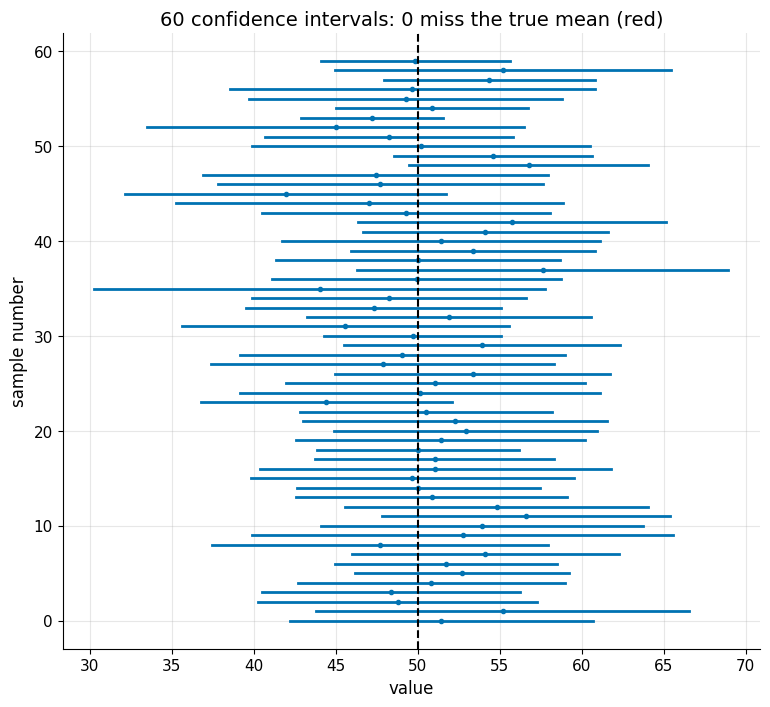

coverage over 200,000 samples: t interval 0.9502, using 1.96 instead 0.9177


In [7]:
true_mu, true_sd, n = 50.0, 12.0, 10
samples = rng.normal(true_mu, true_sd, (60, n))
means, ses = samples.mean(axis=1), samples.std(axis=1, ddof=1) / np.sqrt(n)
half = stats.t.ppf(0.975, n - 1) * ses
miss = (means - half > true_mu) | (means + half < true_mu)
fig, ax = plt.subplots(figsize=(9, 8))
for i in range(60):
    ax.plot([means[i] - half[i], means[i] + half[i]], [i, i], color=HIGHLIGHT if miss[i] else MAIN, linewidth=2)
    ax.plot(means[i], i, "o", color=HIGHLIGHT if miss[i] else MAIN, markersize=3)
ax.axvline(true_mu, color="black", linestyle="--")
ax.set_title(f"60 confidence intervals: {int(miss.sum())} miss the true mean (red)")
ax.set_xlabel("value"); ax.set_ylabel("sample number")
plt.show()
reps = rng.normal(true_mu, true_sd, (200_000, n))
m, s = reps.mean(axis=1), reps.std(axis=1, ddof=1)
coverage_t = np.mean(np.abs(m - true_mu) <= stats.t.ppf(0.975, n - 1) * s / np.sqrt(n))
coverage_z = np.mean(np.abs(m - true_mu) <= 1.96 * s / np.sqrt(n))
print(f"coverage over 200,000 samples: t interval {coverage_t:.4f}, using 1.96 instead {coverage_z:.4f}")
assert abs(coverage_t - 0.95) < 0.002

## 8. 3D visuals

### 8.1 Static: the standard error over (n, sigma)
$\mathrm{SE}=\sigma/\sqrt n$ is a simple but instructive surface: it falls steeply at small $n$ and flattens, and it scales linearly with $\sigma$. Halving the SE is a move that costs four times the sample size.

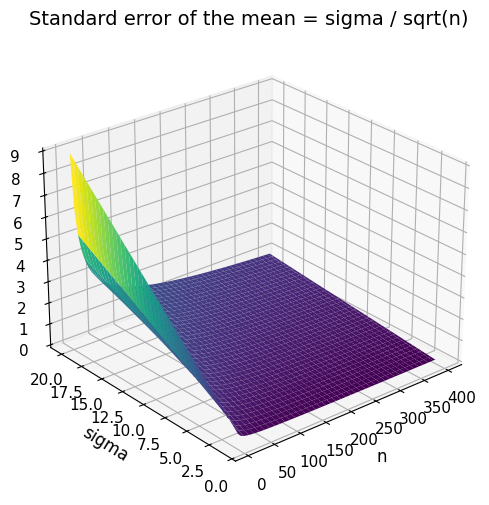

In [8]:
n_axis = np.arange(5, 401, 5)
sigma_axis = np.linspace(1, 20, 40)
SE = sigma_axis[:, None] / np.sqrt(n_axis[None, :])
Ng, Sg = np.meshgrid(n_axis, sigma_axis)
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Ng, Sg, SE, cmap="viridis", edgecolor="none")
ax.set_title("Standard error of the mean = sigma / sqrt(n)")
ax.set_xlabel("n"); ax.set_ylabel("sigma"); ax.set_zlabel("standard error")
ax.view_init(elev=26, azim=-130)
plt.show()

### 8.2 Static: the joint sampling distribution of the mean and the standard deviation
For Normal data $\bar X$ and $s$ are **independent**: their joint density is a product, so the picture is a clean 'hill' with no tilt. For a skewed (Exponential) population they are strongly **dependent**: samples with a large mean also tend to have a large standard deviation. This dependence is why the t interval is imperfect for skewed data.

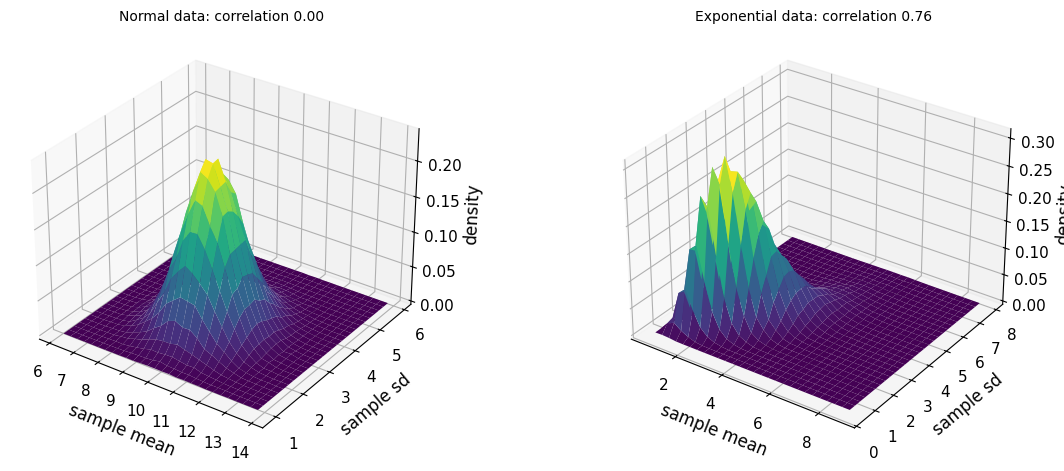

In [9]:
def joint_hist(sampler, n, reps=200_000, bins=28, xlim=None, ylim=None):
    d = sampler((reps, n))
    m, s = d.mean(axis=1), d.std(axis=1, ddof=1)
    return np.histogram2d(m, s, bins=bins, range=[xlim, ylim], density=True), np.corrcoef(m, s)[0, 1]

(normal_h, xe, ye), corr_normal = joint_hist(lambda size: rng.normal(10, 3, size), 10, xlim=(6, 14), ylim=(0.8, 6))
(expo_h, xe2, ye2), corr_expo = joint_hist(lambda size: rng.exponential(3, size), 10, xlim=(0.5, 9), ylim=(0.3, 8))
fig = plt.figure(figsize=(14, 5.5))
for k, (h, xe_, ye_, title) in enumerate([(normal_h, xe, ye, f"Normal data: correlation {corr_normal:.2f}"), (expo_h, xe2, ye2, f"Exponential data: correlation {corr_expo:.2f}")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    X, Y = np.meshgrid((xe_[:-1] + xe_[1:]) / 2, (ye_[:-1] + ye_[1:]) / 2, indexing="ij")
    ax.plot_surface(X, Y, h, cmap="viridis", edgecolor="none")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("sample mean"); ax.set_ylabel("sample sd"); ax.set_zlabel("density")
    ax.view_init(elev=30, azim=-55)
plt.show()
assert abs(corr_normal) < 0.01 and corr_expo > 0.5

### 8.3 Interactive Plotly version of the Normal joint density
Rotate: the joint density of $(\bar X,s)$ for Normal data is the product of a Normal in the mean and a scaled chi in $s$.

In [10]:
mg, sg = np.meshgrid(np.linspace(6, 14, 80), np.linspace(0.8, 6, 80))
n_, mu_, sd_ = 10, 10.0, 3.0
# density of xbar ~ Normal(mu, sd^2/n) times density of s, where (n-1) s^2 / sd^2 ~ chi-square(n-1)
dens = stats.norm(mu_, sd_ / np.sqrt(n_)).pdf(mg) * stats.chi2(n_ - 1).pdf((n_ - 1) * sg**2 / sd_**2) * 2 * (n_ - 1) * sg / sd_**2
fig = go.Figure(go.Surface(x=mg[0], y=sg[:, 0], z=dens, colorscale="Viridis"))
fig.update_layout(title="Joint density of the sample mean and sample sd (Normal data, n = 10)", width=750, height=550,
                  scene=dict(xaxis_title="sample mean", yaxis_title="sample sd", zaxis_title="density"))
fig.show()

## 9. Simulation vs theory

### 9.1 Standard errors of several statistics, simulation against formula
For a Normal population ($\sigma=10$), $n=50$: the formulas of Section 4 against 100,000 simulated samples.

In [11]:
sigma, n, reps = 10.0, 50, 100_000
d = rng.normal(100, sigma, (reps, n))
d2 = rng.normal(100, sigma, (reps, n))
p_hat = rng.binomial(n, 0.3, reps) / n
table = pd.DataFrame({
    "statistic": ["mean", "median", "proportion (p = 0.3)", "difference of two means", "sample variance s^2"],
    "simulated SE": [d.mean(axis=1).std(), np.median(d, axis=1).std(), p_hat.std(), (d.mean(axis=1) - d2.mean(axis=1)).std(), d.var(axis=1, ddof=1).std()],
    "formula": [sigma / np.sqrt(n), 1.2533 * sigma / np.sqrt(n), np.sqrt(0.3 * 0.7 / n), np.sqrt(2) * sigma / np.sqrt(n), sigma**2 * np.sqrt(2 / (n - 1))]})
table["ratio"] = table["simulated SE"] / table["formula"]
print(table.round(4).to_string(index=False))
assert (abs(table["ratio"] - 1) < 0.02).all()

              statistic  simulated SE  formula  ratio
                   mean        1.4132   1.4142 0.9993
                 median        1.7490   1.7724 0.9868
   proportion (p = 0.3)        0.0647   0.0648 0.9991
difference of two means        2.0030   2.0000 1.0015
    sample variance s^2       20.2029  20.2031 1.0000


### 9.2 Coverage of the t interval, and of the Wald interval for a proportion
The nominal 95 % holds for the t interval with Normal data at every $n$. For proportions the simple Wald interval $\hat p\pm1.96\sqrt{\hat p(1-\hat p)/n}$ can fall far short when $np$ is small, the same Normal-approximation issue as in 04_02.

In [12]:
rows = []
for n in [10, 30, 100, 400]:
    for p in [0.05, 0.3]:
        k = rng.binomial(n, p, 400_000)
        phat = k / n
        se = np.sqrt(phat * (1 - phat) / n)
        wald = np.mean(np.abs(phat - p) <= 1.96 * se)
        lo_w = (k + 1.92) / (n + 3.84) - 1.96 * np.sqrt((k + 1.92) * (n - k + 1.92) / (n + 3.84) ** 3)   # Agresti-Coull style adjusted interval
        hi_w = (k + 1.92) / (n + 3.84) + 1.96 * np.sqrt((k + 1.92) * (n - k + 1.92) / (n + 3.84) ** 3)
        adjusted = np.mean((lo_w <= p) & (p <= hi_w))
        rows.append({"n": n, "p": p, "n p": n * p, "Wald coverage": wald, "adjusted (add 2 successes, 2 failures) coverage": adjusted})
print(pd.DataFrame(rows).round(4).to_string(index=False))

  n    p   n p  Wald coverage  adjusted (add 2 successes, 2 failures) coverage
 10 0.05   0.5         0.3995                                           0.9887
 10 0.30   3.0         0.8405                                           0.9528
 30 0.05   1.5         0.7818                                           0.9846
 30 0.30   9.0         0.9526                                           0.9504
100 0.05   5.0         0.8776                                           0.9658
100 0.30  30.0         0.9505                                           0.9498
400 0.05  20.0         0.9272                                           0.9507
400 0.30 120.0         0.9505                                           0.9439


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [13]:
x = rng.gamma(4, 7.5, 40)
print("sample mean, std (ddof=1):", round(x.mean(), 3), round(x.std(ddof=1), 3), "| SE:", round(stats.sem(x), 4))
print("t interval:", np.round(stats.t.interval(0.95, df=x.size - 1, loc=x.mean(), scale=stats.sem(x)), 3))
print("Normal interval for comparison:", np.round(stats.norm.interval(0.95, loc=x.mean(), scale=stats.sem(x)), 3))
print("chi-square based interval for sigma^2:", np.round([(x.size - 1) * x.var(ddof=1) / stats.chi2.ppf(q, x.size - 1) for q in (0.975, 0.025)], 2))
print("SE of a proportion 12/80:", round(np.sqrt(0.15 * 0.85 / 80), 4), "; proportion CI (scipy.stats.binomtest):", np.round(stats.binomtest(12, 80).proportion_ci(confidence_level=0.95, method="wilson"), 4))
print("finite population correction for n = 40, N = 200:", round(np.sqrt((200 - 40) / 199), 4))

sample mean, std (ddof=1): 30.709 13.967 | SE: 2.2084
t interval: [26.242 35.176]
Normal interval for comparison: [26.381 35.038]
chi-square based interval for sigma^2: [130.91 321.65]
SE of a proportion 12/80: 0.0399 ; proportion CI (scipy.stats.binomtest): [0.0879 0.2441]
finite population correction for n = 40, N = 200: 0.8967


## 11. Real-world worked examples

---
### Example 1 (main): estimating the average delivery time from a sample

**Scenario.** A courier company has $N=20{,}000$ deliveries this month (the population of Section 7.1: mean $\mu\approx30$ minutes, standard deviation $\sigma\approx15$ minutes, right-skewed). An analyst times a random sample of **$n=40$** deliveries (without replacement).

**Questions**
1. What is the standard error of the sample mean, with and without the finite population correction?
2. What is the probability that the sample mean exceeds **33 minutes**?
3. For one actual sample, what is the 95 % confidence interval for the true mean? What does the 95 % mean?
4. How large must the sample be so that the **standard error is at most 1 minute**, and so that the **95 % margin of error is at most 1 minute**?

### 11.1 By hand
With the exact population values $\mu=30.04$ and $\sigma=15.07$ (computed in code):

**Q1.** $\mathrm{SE}=\sigma/\sqrt n=15.07/\sqrt{40}=2.382$. Correction factor $\sqrt{(N-n)/(N-1)}=\sqrt{19960/19999}=0.99902$, so $\mathrm{SE}=2.380$ (the correction is irrelevant: $n/N=0.2\,\%$).

**Q2.** $z=\dfrac{33-30.04}{2.380}=1.243$, so $P(\bar X>33)\approx1-\Phi(1.243)=0.107$ (CLT; the parent skewness is about 1, so $n=40$ is adequate).

**Q3.** $\bar x\pm t_{39,0.975}\,s/\sqrt n=\bar x\pm2.023\,s/\sqrt{40}$, with the values from one specific simulated sample in code. The 95 % is a property of the *method*: 95 % of intervals built this way (over repeated samples) contain $\mu$.

**Q4.** SE $\le1$: $n\ge\sigma^2=227$. Margin $1.96\,\sigma/\sqrt n\le1$: $n\ge(1.96\cdot15.07)^2=872.4$, so **872**.

In [14]:
import math

n_sample = 40
se_plain = sigma_pop / math.sqrt(n_sample)
fpc = math.sqrt((N - n_sample) / (N - 1))
se_corrected = se_plain * fpc
print(f"Q1: sigma = {sigma_pop:.3f}; SE = {se_plain:.4f}; correction factor {fpc:.5f}; corrected SE = {se_corrected:.4f}")

def standard_normal_sf(z):
    return 0.5 * math.erfc(z / math.sqrt(2))
z = (33 - mu_pop) / se_corrected
print(f"Q2: z = {z:.3f}; P(sample mean > 33) = {standard_normal_sf(z):.4f}")

sample_rng = np.random.default_rng(99)
one_sample = population[sample_rng.choice(N, n_sample, replace=False)]
xbar, s = one_sample.mean(), one_sample.std(ddof=1)
t_crit = 2.0226                                                         # t(0.975, 39 d.f.), table value
half_width = t_crit * s / math.sqrt(n_sample)
print(f"Q3: this sample: mean {xbar:.3f}, s {s:.3f}, SE estimate {s / math.sqrt(n_sample):.3f}; 95 % CI = ({xbar - half_width:.2f}, {xbar + half_width:.2f})")

n_for_se = math.ceil(sigma_pop**2 / 1.0**2)
n_for_margin = math.ceil((1.959964 * sigma_pop / 1.0) ** 2)
print(f"Q4: n for SE <= 1: {n_for_se}; n for margin of error <= 1 at 95 %: {n_for_margin}")

Q1: sigma = 15.066; SE = 2.3821; correction factor 0.99902; corrected SE = 2.3797
Q2: z = 1.243; P(sample mean > 33) = 0.1069
Q3: this sample: mean 29.453, s 15.584, SE estimate 2.464; 95 % CI = (24.47, 34.44)
Q4: n for SE <= 1: 227; n for margin of error <= 1 at 95 %: 872


### 11.2 In code with `scipy`, and the asserts

In [15]:
assert np.isclose(se_plain, sigma_pop / np.sqrt(n_sample))
assert np.isclose(standard_normal_sf(z), stats.norm(mu_pop, se_corrected).sf(33))
lo, hi = stats.t.interval(0.95, df=n_sample - 1, loc=xbar, scale=stats.sem(one_sample))
assert np.isclose(lo, xbar - half_width, atol=0.01) and np.isclose(hi, xbar + half_width, atol=0.01)
assert n_for_margin == int(np.ceil((stats.norm.isf(0.025) * sigma_pop) ** 2))
print("t critical value:", round(stats.t.ppf(0.975, n_sample - 1), 4), "| the interval from scipy:", np.round((lo, hi), 2), "| true mean:", round(mu_pop, 2), "| inside:", bool(lo <= mu_pop <= hi))

t critical value: 2.0227 | the interval from scipy: [24.47 34.44] | true mean: 30.04 | inside: True


### 11.3 Verify by simulation (repeated sampling from the finite population)

In [16]:
sim_rng = np.random.default_rng(7)
reps = 30_000
idx = np.array([sim_rng.choice(N, size=n_sample, replace=False) for _ in range(reps)])
samples = population[idx]
means = samples.mean(axis=1)
print(f"Q1: simulated SE {means.std():.4f} vs corrected formula {se_corrected:.4f}")
print(f"Q2: simulated P(mean > 33) {np.mean(means > 33):.4f} vs CLT {stats.norm(mu_pop, se_corrected).sf(33):.4f}")
ses = samples.std(axis=1, ddof=1) / np.sqrt(n_sample)
half = stats.t.ppf(0.975, n_sample - 1) * ses
covered = np.abs(means - mu_pop) <= half
print(f"Q3: coverage of the 95 % t interval over {reps:,} repeated samples: {covered.mean():.4f}")
assert abs(means.std() / se_corrected - 1) < 0.02 and abs(covered.mean() - 0.95) < 0.01
big = np.array([sim_rng.choice(N, size=n_for_margin, replace=False) for _ in range(3000)])
print(f"Q4: with n = {n_for_margin} the sample mean is within 1 minute of the truth in {np.mean(np.abs(population[big].mean(axis=1) - mu_pop) <= 1):.4f} of samples (target 0.95)")

Q1: simulated SE 2.3877 vs corrected formula 2.3797
Q2: simulated P(mean > 33) 0.1103 vs CLT 0.1069
Q3: coverage of the 95 % t interval over 30,000 repeated samples: 0.9445
Q4: with n = 872 the sample mean is within 1 minute of the truth in 0.9540 of samples (target 0.95)


### 11.4 Plots with the regions shaded

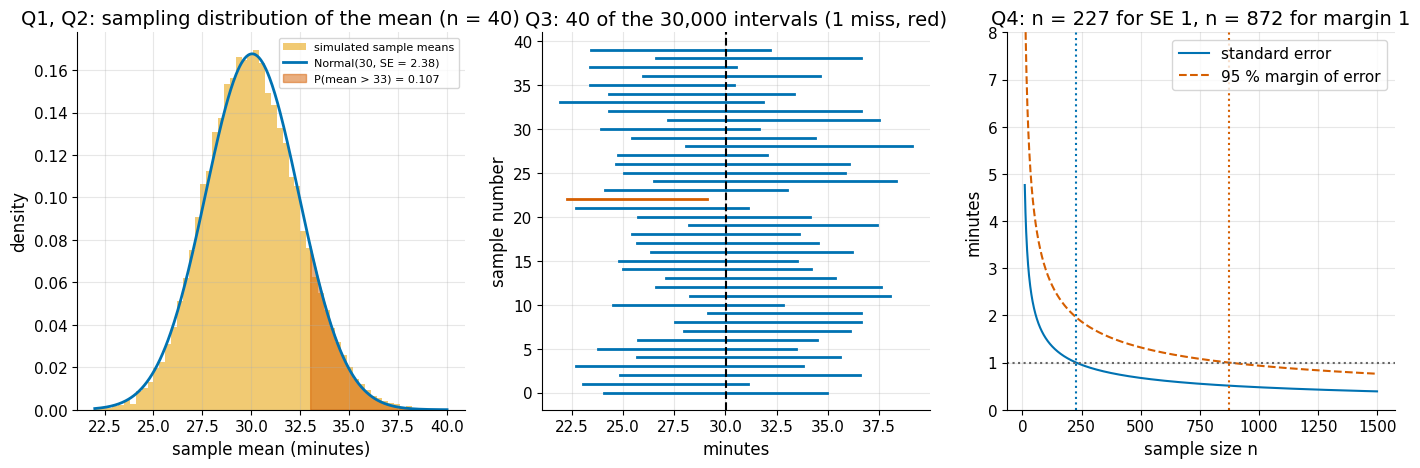

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9))
x = np.linspace(22, 40, 400)
axes[0].hist(means, bins=60, range=(22, 40), density=True, color=SIM, alpha=0.55, label="simulated sample means")
axes[0].plot(x, stats.norm(mu_pop, se_corrected).pdf(x), color=MAIN, linewidth=2, label=f"Normal(30, SE = {se_corrected:.2f})")
axes[0].fill_between(x[x > 33], stats.norm(mu_pop, se_corrected).pdf(x[x > 33]), color=HIGHLIGHT, alpha=0.5, label=f"P(mean > 33) = {standard_normal_sf(z):.3f}")
axes[0].set_title("Q1, Q2: sampling distribution of the mean (n = 40)")
axes[0].set_xlabel("sample mean (minutes)"); axes[0].set_ylabel("density"); axes[0].legend(fontsize=8)
for i in range(40):
    c = MAIN if covered[i] else HIGHLIGHT
    axes[1].plot([means[i] - half[i], means[i] + half[i]], [i, i], color=c, linewidth=2)
axes[1].axvline(mu_pop, color="black", linestyle="--")
axes[1].set_title(f"Q3: 40 of the 30,000 intervals ({int((~covered[:40]).sum())} miss, red)")
axes[1].set_xlabel("minutes"); axes[1].set_ylabel("sample number")
ns = np.arange(10, 1500)
axes[2].plot(ns, sigma_pop / np.sqrt(ns), color=MAIN, label="standard error")
axes[2].plot(ns, 1.959964 * sigma_pop / np.sqrt(ns), "--", color=HIGHLIGHT, label="95 % margin of error")
axes[2].axhline(1, color=NEUTRAL, linestyle=":")
axes[2].axvline(n_for_se, color=MAIN, linestyle=":"); axes[2].axvline(n_for_margin, color=HIGHLIGHT, linestyle=":")
axes[2].set_ylim(0, 8)
axes[2].set_title(f"Q4: n = {n_for_se} for SE 1, n = {n_for_margin} for margin 1")
axes[2].set_xlabel("sample size n"); axes[2].set_ylabel("minutes"); axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
See the printed numbers above. In words:
- A sample of 40 deliveries pins the mean down to a **standard error of about 2.4 minutes** (2.38 by the formula, 2.39 in the repeated-sampling simulation); the sampling fraction is only 0.2 %, so the finite population correction changes nothing.
- A sample mean above 33 minutes happens about **11 % of the time** (10.7 % by the CLT, 11.0 % simulated) even though the true mean is 30: a single sample of 40 can easily look 'worse' by 3 minutes by chance. Do not react to one sample.
- The reported interval has the form (mean ± about 5 minutes): for our sample (24.5, 34.4). Its 95 % describes the **method**: over 30,000 repeated samples 94.5 % of such intervals contained the true mean, a little under 95 % because the population is skewed (05_02).
- **Decision:** to report the average delivery time to within one minute you need **about 872 deliveries**, and every halving of that margin costs four times as many. If a precision of ±2 minutes is enough, **about 218** is enough.

---
### Example 2: a defect rate and its standard error

**Scenario (illustrative).** An inspector samples **n = 80** items and finds **12 defective** ($\hat p=0.15$). What is the standard error of $\hat p$, a 95 % interval, and how reliable is the simple (Wald) interval here?

**By hand.** $\mathrm{SE}=\sqrt{0.15\cdot0.85/80}=0.0399$; Wald interval $0.15\pm1.96\cdot0.0399=(0.072,\,0.228)$.

In [18]:
k_def, n_def = 12, 80
p_hat = k_def / n_def
se_p = math.sqrt(p_hat * (1 - p_hat) / n_def)
wald = (p_hat - 1.959964 * se_p, p_hat + 1.959964 * se_p)
wilson = stats.binomtest(k_def, n_def).proportion_ci(confidence_level=0.95, method="wilson")
exact = stats.binomtest(k_def, n_def).proportion_ci(confidence_level=0.95, method="exact")
print(f"p-hat {p_hat:.4f}, SE {se_p:.4f}; Wald ({wald[0]:.4f}, {wald[1]:.4f}); Wilson ({wilson.low:.4f}, {wilson.high:.4f}); exact ({exact.low:.4f}, {exact.high:.4f})")
assert np.isclose(se_p, 0.0399, atol=1e-4)
# coverage of each method when the true rate is 0.15 and n = 80
true_p = 0.15
k = rng.binomial(n_def, true_p, 400_000)
ph = k / n_def
cover_wald = np.mean(np.abs(ph - true_p) <= 1.959964 * np.sqrt(ph * (1 - ph) / n_def))
z2 = 1.959964**2
centre = (ph + z2 / (2 * n_def)) / (1 + z2 / n_def)
half_w = 1.959964 * np.sqrt(ph * (1 - ph) / n_def + z2 / (4 * n_def**2)) / (1 + z2 / n_def)
cover_wilson = np.mean(np.abs(centre - true_p) <= half_w)
print(f"coverage at p = 0.15, n = 80: Wald {cover_wald:.4f}, Wilson {cover_wilson:.4f}")

p-hat 0.1500, SE 0.0399; Wald (0.0718, 0.2282); Wilson (0.0879, 0.2441); exact (0.0800, 0.2474)
coverage at p = 0.15, n = 80: Wald 0.9140, Wilson 0.9602


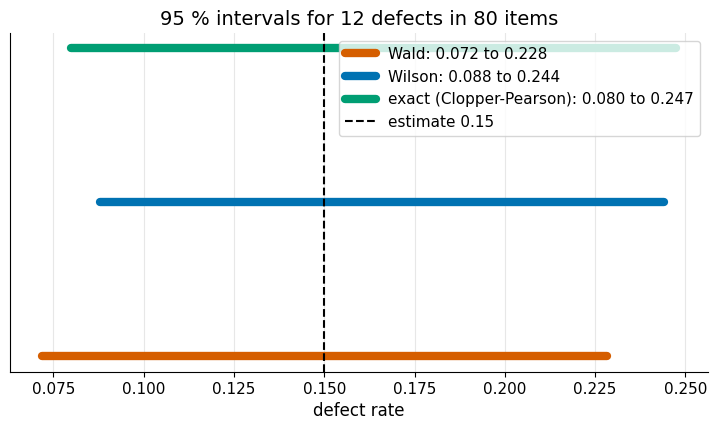

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.4))
for y, (name, (lo_, hi_), color) in enumerate([("Wald", wald, HIGHLIGHT), ("Wilson", (wilson.low, wilson.high), MAIN), ("exact (Clopper-Pearson)", (exact.low, exact.high), COLORS[2])]):
    ax.plot([lo_, hi_], [y, y], color=color, linewidth=6, solid_capstyle="round", label=f"{name}: {lo_:.3f} to {hi_:.3f}")
ax.axvline(p_hat, color="black", linestyle="--", label="estimate 0.15")
ax.set_yticks([]); ax.set_xlabel("defect rate"); ax.set_title("95 % intervals for 12 defects in 80 items")
ax.legend(loc="upper right")
plt.show()

**Interpretation.** The estimate 15 % has a standard error of **4 percentage points**, so the 95 % interval is roughly **7 % to 23 %**: a sample of 80 cannot say whether the defect rate is 10 % or 20 %. The three interval methods agree closely here (the Wald interval sits lower and is too narrow: it covers only 91.4 % of the time here, against 96.0 % for the Wilson interval), and the gap widens for small $np$ (see 9.2). **Decision:** to learn the defect rate to within ±2 points you need about **1,200 items** ($1.96^2\cdot0.15\cdot0.85/0.02^2$), roughly 15 times the current sample.

---
### Example 3: comparing two checkout designs (standard error of a difference)

**Scenario (illustrative).** Design A: **n₁ = 50** customers, mean checkout time **142 s**, SD **40 s**. Design B: **n₂ = 60** customers, mean **131 s**, SD **35 s**. Is the 11-second difference more than sampling noise?

**By hand.** $\mathrm{SE}=\sqrt{40^2/50+35^2/60}=\sqrt{32+20.42}=7.24$. The difference is $11/7.24=1.52$ standard errors; the 95 % interval is $11\pm1.96\cdot7.24=(-3.2,\,25.2)$ seconds.

difference 11.0 s, SE 7.240 s, z = 1.519; Welch d.f. 98.3; 95 % CI (-3.37, 25.37); two-sided p-value 0.1319


simulation of the difference: SD 7.235 (formula 7.240); share of studies where the sign is reversed if the true difference is 11: 0.0639


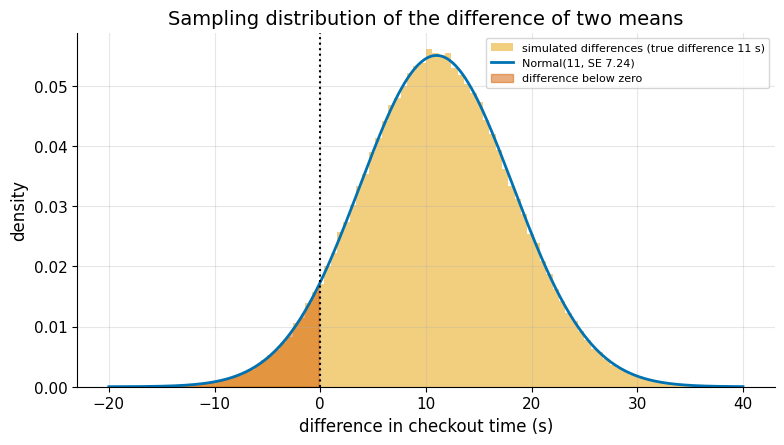

In [20]:
m1, s1, n1, m2, s2, n2 = 142.0, 40.0, 50, 131.0, 35.0, 60
diff = m1 - m2
se_diff = math.sqrt(s1**2 / n1 + s2**2 / n2)
welch_df = (s1**2 / n1 + s2**2 / n2) ** 2 / ((s1**2 / n1) ** 2 / (n1 - 1) + (s2**2 / n2) ** 2 / (n2 - 1))
t_crit = stats.t.ppf(0.975, welch_df)
print(f"difference {diff:.1f} s, SE {se_diff:.3f} s, z = {diff / se_diff:.3f}; Welch d.f. {welch_df:.1f}; 95 % CI ({diff - t_crit * se_diff:.2f}, {diff + t_crit * se_diff:.2f}); two-sided p-value {2 * stats.t.sf(diff / se_diff, welch_df):.4f}")
assert np.isclose(se_diff, 7.24, atol=1e-2)
sim = rng.normal(m1, s1, (300_000, n1)).mean(axis=1) - rng.normal(m2, s2, (300_000, n2)).mean(axis=1)
print(f"simulation of the difference: SD {sim.std():.3f} (formula {se_diff:.3f}); share of studies where the sign is reversed if the true difference is 11: {np.mean(sim < 0):.4f}")
x = np.linspace(-20, 40, 400)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.hist(sim, bins=100, range=(-20, 40), density=True, color=SIM, alpha=0.5, label="simulated differences (true difference 11 s)")
ax.plot(x, stats.norm(diff, se_diff).pdf(x), color=MAIN, linewidth=2, label="Normal(11, SE 7.24)")
ax.fill_between(x[x < 0], stats.norm(diff, se_diff).pdf(x[x < 0]), color=HIGHLIGHT, alpha=0.5, label="difference below zero")
ax.axvline(0, color="black", linestyle=":")
ax.set_title("Sampling distribution of the difference of two means")
ax.set_xlabel("difference in checkout time (s)"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.show()

**Interpretation.** The observed 11-second gain is only about **1.5 standard errors** away from zero, and the 95 % interval **includes zero** (roughly -3 to +25 seconds). If the true gain were 11 seconds, about 6 % of repeated studies of this size would show the *wrong* sign. **Decision:** the data are suggestive, not conclusive; to cut the standard error in half you need four times the customers (about 200 per design). Module 06 turns this comparison into a formal test.

## 12. Where it is used

### Statistics
- **Confidence intervals and hypothesis tests** are statements about sampling distributions; the t, chi-square and F distributions *are* sampling distributions.
- **Survey sampling, polling and quality control** (finite population correction, design effects); estimating sample sizes from a target standard error.

### Data science
- **Error bars and dashboards:** every metric on a dashboard should come with a standard error, especially for small segments.
- **A/B tests:** the standard error of a difference of proportions or means is the denominator of the test statistic (Example 3).

### ML and AI
- **Model evaluation:** a test accuracy measured on $n$ examples has standard error $\sqrt{p(1-p)/n}$: comparing two models that differ by less than that is noise (Module 10).
- **Benchmarks, learning curves and seeds:** the variability across training seeds is the sampling distribution of the metric, summarised by its standard error.

## 13. Common pitfalls and misconceptions

- **Standard deviation versus standard error:** the SD describes the data and does not shrink with $n$; the SE describes the estimate and does.
- **Reading the 95 % as a probability about this interval:** the probability statement is about the *procedure* before the data are collected.
- **Overlapping intervals do not mean 'no difference':** the SE of a *difference* is smaller than the sum of the two SEs (it is the root of the sum of squares).
- **Using the plain formula when you sample a big fraction of a small population:** apply the finite population correction.
- **Dividing by $n$ instead of $n-1$** for the sample variance of a small sample (biased low).
- **Forgetting that the SE only measures random error:** a biased or non-random sample has a tiny SE and a wrong answer.
- **Wald interval for small counts or rare events:** use Wilson or exact intervals.
- **Using 1.96 with a small sample and an estimated SD:** use the t quantile (7.6).

## 14. Exercises

1. A random sample of 25 bolts has mean length 50.3 mm and standard deviation 0.8 mm (Normal lengths). Give a 95 % confidence interval for the true mean length, and say what changes if the sample were 100 bolts with the same mean and SD.
2. A poll of 1,000 voters finds 540 in favour. Compute the SE of the proportion and a 95 % Wald interval. How many voters are needed for a margin of ±2 points?
3. Draw 100,000 samples of size 4 from Normal(0, 1) and compute $s^2$ with divisor $n$ and with divisor $n-1$. Verify the bias factor $(n-1)/n$ and compare the variances of the two estimators.
4. Sampling 150 students without replacement from a school of 600, the SD of exam scores is 12. What is the SE of the mean score with and without the finite population correction?
5. For Normal data, show by simulation that the sample median has SE about 1.25 times that of the mean at $n=100$, and that for the Laplace (double-exponential) distribution the median is *better* than the mean.
6. (Harder) Use $\mathrm{Var}(\chi^2_{n-1})=2(n-1)$ to show that $\mathrm{SE}(s^2)=\sigma^2\sqrt{2/(n-1)}$ for Normal data, and compute the relative SE of $s$ for $n=10$ and $n=100$ (approximately $1/\sqrt{2(n-1)}$).

Solutions are at the end.

## 15. Summary table

| Statistic | Standard error | Sampling distribution (Normal data) | Note |
|---|---|---|---|
| Mean | sigma / sqrt(n) | Normal(mu, sigma^2 / n) | CLT for other parents |
| Studentized mean | | t with n - 1 d.f. | estimating sigma costs tail weight |
| Sample variance | sigma^2 sqrt(2 / (n - 1)) | (n-1) s^2 / sigma^2 is chi-square(n - 1) | divide by n - 1 |
| Proportion | sqrt(p (1 - p) / n) | Binomial / n | Wilson or exact for small n p |
| Difference of means | sqrt(s1^2 / n1 + s2^2 / n2) | approx Normal (Welch t) | not the sum of the two SEs |
| Median | about 1.2533 sigma / sqrt(n) | approx Normal | robust, 25 % noisier for Normal data |
| Mean without replacement | sigma / sqrt(n) sqrt((N - n) / (N - 1)) | | matters when n / N above 5 % |

## Solutions

In [21]:
n, xbar, s = 25, 50.3, 0.8
t = stats.t.ppf(0.975, n - 1)
print("1: 95 % CI for 25 bolts:", np.round((xbar - t * s / 5, xbar + t * s / 5), 3), "| for 100 bolts:", np.round(stats.t.interval(0.95, 99, loc=xbar, scale=s / 10), 3))
p, n = 0.54, 1000
se = np.sqrt(p * (1 - p) / n)
print("2: SE", round(se, 4), "CI", np.round((p - 1.96 * se, p + 1.96 * se), 4), "; n for +/- 2 points (worst case p = 0.5):", int(np.ceil(1.96**2 * 0.25 / 0.02**2)))
d = rng.normal(0, 1, (100_000, 4))
v0, v1 = d.var(axis=1, ddof=0), d.var(axis=1, ddof=1)
print("3: means", round(v0.mean(), 4), round(v1.mean(), 4), "(theory 0.75 and 1); variances", round(v0.var(), 4), round(v1.var(), 4), "(ratio", round(v0.var() / v1.var(), 3), "= ((n-1)/n)^2 =", 0.5625, ")")
print("4: SE without correction", round(12 / np.sqrt(150), 4), "; with correction", round(12 / np.sqrt(150) * np.sqrt((600 - 150) / 599), 4))
for name, gen in (("Normal", lambda size: rng.normal(0, 1, size)), ("Laplace", lambda size: rng.laplace(0, 1 / np.sqrt(2), size))):
    x = gen((40_000, 100))
    print("5:", name, "SE of median / SE of mean =", round(np.median(x, axis=1).std() / x.mean(axis=1).std(), 3))
for n in (10, 100):
    print("6: n =", n, "relative SE of s^2:", round(np.sqrt(2 / (n - 1)), 4), "; relative SE of s (approx):", round(1 / np.sqrt(2 * (n - 1)), 4))

1: 95 % CI for 25 bolts: [49.97 50.63] | for 100 bolts: [50.141 50.459]
2: SE 0.0158 CI [0.5091 0.5709] ; n for +/- 2 points (worst case p = 0.5): 2401
3: means 0.7508 1.001 (theory 0.75 and 1); variances 0.3759 0.6683 (ratio 0.563 = ((n-1)/n)^2 = 0.5625 )
4: SE without correction 0.9798 ; with correction 0.8492
5: Normal SE of median / SE of mean = 1.249


5: Laplace SE of median / SE of mean = 0.756
6: n = 10 relative SE of s^2: 0.4714 ; relative SE of s (approx): 0.2357
6: n = 100 relative SE of s^2: 0.1421 ; relative SE of s (approx): 0.0711


**1.** For 25 bolts the interval is $50.3\pm2.064\cdot0.16=(49.97,\,50.63)$; with 100 bolts it narrows to $\pm0.159$ (about half as wide), because the SE halves and the t multiplier is slightly smaller.

**2.** $\mathrm{SE}=0.0158$, Wald interval $(0.509,\,0.571)$; for a worst-case margin of ±2 points you need $n=2{,}401$.

**3.** Dividing by $n$ gives an average of $0.75$ (biased low), dividing by $n-1$ gives $1.00$; the biased version has the *smaller* variance (ratio $0.5625=((n-1)/n)^2$): the unbiased one pays with variance. For estimating $\sigma^2$ with small $n$ the trade-off is real (mean squared error is actually lower for a divisor of $n+1$), but $n-1$ is the standard because unbiasedness composes well.

**4.** Without correction $12/\sqrt{150}=0.980$; with the correction $0.980\cdot\sqrt{450/599}=0.849$: 13 % smaller because the sample is a quarter of the population.

**5.** For Normal data the ratio is about 1.25, matching $\sqrt{\pi/2}$; for the Laplace distribution the ratio is about 0.76 (the median is roughly 25 % *less* noisy than the mean): heavier tails favour the median.

**6.** $\mathrm{Var}(s^2)=\frac{\sigma^4}{(n-1)^2}\cdot2(n-1)=\frac{2\sigma^4}{n-1}$, so $\mathrm{SE}(s^2)=\sigma^2\sqrt{2/(n-1)}$; the relative SE of $s$ is about half the relative SE of $s^2$: 0.24 at $n=10$ and 0.07 at $n=100$.